In [1]:
# Colab / fresh environment: install the module (builds the C++ core, takes a few minutes the first time)
try:
    import sensor_fusion
except ImportError:
    %pip install -q git+https://github.com/Rudip1/learn-sensor-fusion

# 7 · Map building: aggregating scans, colouring from cameras

**Recap** ([theory](../../1_theory/07_map_building.md)). A sensor's world pose is the vehicle pose times the
mounting, $T_{WS} = T_{WV}T_{VS}$ (7.1). Scans go to the world with their poses (7.2); a heading error $\delta\psi$
moves a point at range $r$ by about $r\,\delta\psi$. A camera sees world points at $(u, v) = \mathbf K\mathbf p^C / z^C$
(7.3). Colouring the map needs an occlusion test (Algorithm 7.1).

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sensor_fusion import fusion, mapping, scenarios as sc, sim
from sensor_fusion.plotting import SERIES, use_style

use_style()
scene = sim.demo_scene()
t, truth = sc.lane_drive()                         # 50 m at 2 m/s, poses at 10 Hz
T_vl = np.eye(4); T_vl[:3, 3] = [0, 0, 1.8]        # LiDAR 1.8 m above the vehicle origin
model = sim.LidarModel.spinning(16, -15.0, 15.0, 720, 60.0)
model.range_noise = 0.02
idx = np.arange(0, len(t), 5)                      # a scan every 0.5 s
scans = [sim.simulate_lidar(scene, mapping.sensor_pose(truth[k], T_vl), model, int(k)) for k in idx]
pts = [s["points"] for s in scans]
labels = np.concatenate([s["labels"] for s in scans])
print(f"{len(scans)} scans, {sum(len(p) for p in pts)} points")

51 scans, 459705 points


### ✏️ Exercise 1 — the sensor pose
Implement `sensor_pose(xy_yaw, T_vs)` with eq. (7.1) and compare with `mapping.sensor_pose`.

In [3]:
def sensor_pose(p, T_vs):
    ### BEGIN SOLUTION
    c, s = np.cos(p[2]), np.sin(p[2])
    T_wv = np.array([[c, -s, 0, p[0]], [s, c, 0, p[1]], [0, 0, 1, 0], [0, 0, 0, 1.0]])
    return T_wv @ T_vs
    ### END SOLUTION

In [4]:
T_vs = sc.forward_camera_mount()
for p in truth[::50]:
    assert np.allclose(sensor_pose(p, T_vs), mapping.sensor_pose(p, T_vs))
print("✅ sensor_pose")

✅ sensor_pose


## 1. The map and its blur

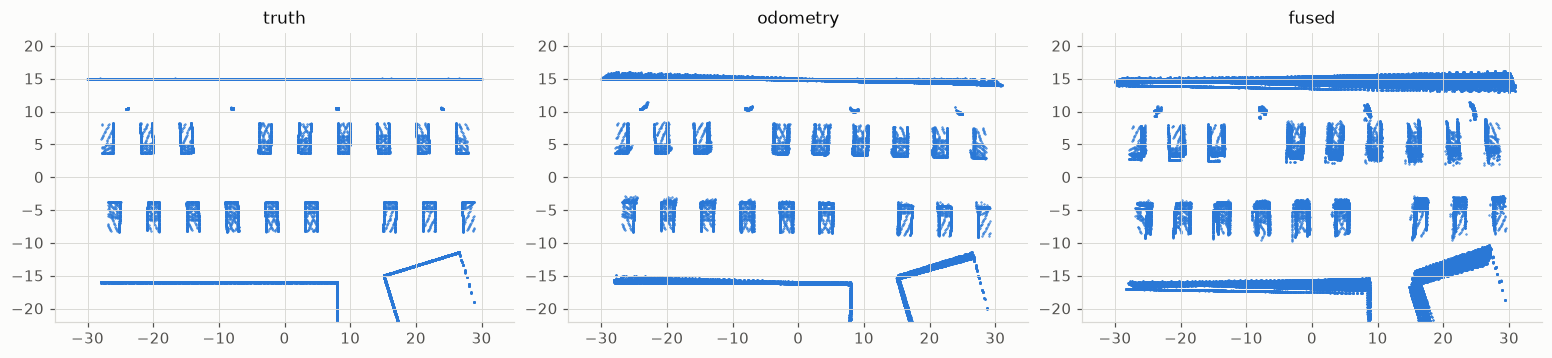

In [5]:
true_map = mapping.aggregate(pts, [mapping.sensor_pose(truth[k], T_vl) for k in idx])["points"]
noise = fusion.OdometryNoise()
odo = sc.drifting_odometry(truth, noise, 0.01, rng=1)
tg, zg, _ = sc.gnss_fixes(t, truth, 1.0, 1.5, rng=2)
fused = fusion.fuse(list(t), odo, list(tg), zg, np.full((len(tg), 2), 2.25), truth[0], np.diag([1, 1, np.radians(5) ** 2]), noise)["x"]
fig, ax = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for a, (name, pose) in zip(ax, (("truth", truth), ("odometry", odo), ("fused", fused))):
    M = mapping.aggregate(pts, [mapping.sensor_pose(pose[k], T_vl) for k in idx], 0.2)["points"]
    walls = M[:, 2] > 0.3                           # leave the ground out of the picture
    a.scatter(M[walls, 0], M[walls, 1], s=0.2)
    a.set_aspect("equal"); a.set_xlim(-35, 35); a.set_ylim(-22, 22); a.set_title(name)
plt.show()

### ✏️ Exercise 2 — blur from a heading error
Write `displacement(r, dpsi)`, the distance a point at range r moves when the scan is rotated by dpsi about the
sensor. Check it on a rotated copy of the first scan.

In [6]:
def displacement(r, dpsi):
    ### BEGIN SOLUTION
    return 2 * r * np.abs(np.sin(dpsi / 2))
    ### END SOLUTION

In [7]:
p0 = pts[0]
good = mapping.aggregate([p0], [mapping.sensor_pose(truth[0], T_vl)])["points"]
bad = mapping.aggregate([p0], [mapping.sensor_pose(truth[0] + [0, 0, np.radians(1)], T_vl)])["points"]
r_h = np.linalg.norm(p0[:, :2], axis=1)              # the rotation is about the vertical axis
assert np.allclose(np.linalg.norm(bad - good, axis=1), displacement(r_h, np.radians(1)))
print(f"✅ displacement: 1 degree moves a point at 40 m by {displacement(40, np.radians(1)):.2f} m")

✅ displacement: 1 degree moves a point at 40 m by 0.70 m


## 2. Projection

### ✏️ Exercise 3 — pinhole projection
Implement `project(points_w, T_wc, K, w, h)` returning pixels (n, 2), depths and the inside mask, with eq. (7.3).

In [8]:
def project(points_w, T_wc, K, w, h):
    ### BEGIN SOLUTION
    T_cw = np.linalg.inv(T_wc)
    pc = points_w @ T_cw[:3, :3].T + T_cw[:3, 3]
    z = pc[:, 2]
    with np.errstate(divide="ignore", invalid="ignore"):
        uv = (pc @ K.T)[:, :2] / z[:, None]
    inside = (z > 1e-6) & (uv[:, 0] >= 0) & (uv[:, 1] >= 0) & (uv[:, 0] < w) & (uv[:, 1] < h)
    return uv, z, inside
    ### END SOLUTION

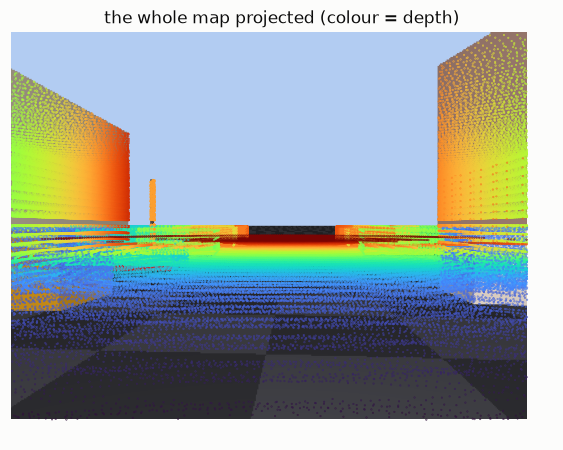

✅ project


In [9]:
cam = sim.Camera(np.array([[300.0, 0, 200], [0, 300, 150], [0, 0, 1]]), 400, 300)
T_wc = mapping.sensor_pose(truth[100], sc.forward_camera_mount())
uv, z, inside = project(true_map, T_wc, cam.K, cam.width, cam.height)
ref = mapping.project(true_map, T_wc, cam)
assert np.array_equal(inside, ref["inside"]) and np.allclose(uv[inside], ref["pixels"][inside])
img = sim.render_camera(scene, T_wc, cam)
plt.imshow(np.clip(img["rgb"], 0, 1)); plt.scatter(*uv[inside].T, s=0.1, c=np.minimum(z[inside], 40), cmap="turbo")
plt.axis("off"); plt.title("the whole map projected (colour = depth)"); plt.show()
print("✅ project")

## 3. Colouring

occlusion test False: (coloured, correct) = (0.669, 0.794)
occlusion test True : (coloured, correct) = (0.417, 0.977)


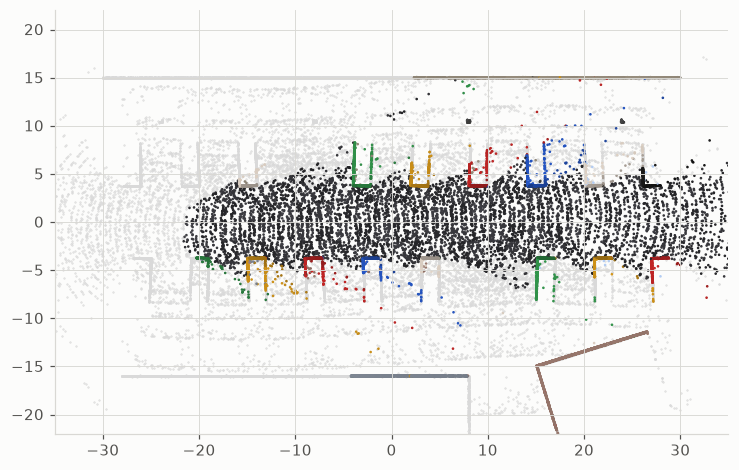

In [10]:
sub = np.random.default_rng(0).choice(len(true_map), 60000, replace=False)
P, L = true_map[sub], labels[sub]
cams = np.arange(0, len(t), 25)
Tc = [mapping.sensor_pose(truth[k], sc.forward_camera_mount()) for k in cams]
images = [sim.render_camera(scene, T, cam) for T in Tc]


def right_surface(colors, images, poses):
    """Fraction of points coloured, and of those the fraction coloured from their own surface."""
    ci = np.array(colors["camera"]); ok = n = 0
    for k, im in enumerate(images):
        sel = np.flatnonzero(ci == k)
        uv = mapping.project(P[sel], poses[k], cam)["pixels"].astype(int)
        ok += np.sum(im["label"][uv[:, 1], uv[:, 0]] == L[sel]); n += len(sel)
    return round(n / len(P), 3), round(float(ok / n), 3)


for occ in (False, True):
    c = mapping.colorize(P, [im["rgb"] for im in images], Tc, cam, occ)
    print(f"occlusion test {occ!s:5s}: (coloured, correct) = {right_surface(c, images, Tc)}")
seen = np.array(c["camera"]) >= 0
plt.figure(figsize=(8, 5))
plt.scatter(P[~seen, 0], P[~seen, 1], s=0.2, color="0.85"); plt.scatter(P[seen, 0], P[seen, 1], s=0.5, c=np.clip(c["rgb"][seen], 0, 1))
plt.gca().set_aspect("equal"); plt.xlim(-35, 35); plt.ylim(-22, 22); plt.show()

## 🔨 Break it — a miscalibrated camera

The camera is really turned by 1° but the map believes the nominal mounting.

In [11]:
for err in (0.5, 1.0, 2.0):
    real = [mapping.sensor_pose(truth[k], sc.forward_camera_mount(yaw_error_deg=err)) for k in cams]
    imgs = [sim.render_camera(scene, T, cam) for T in real]
    c = mapping.colorize(P, [im["rgb"] for im in imgs], Tc, cam)
    print(f"camera yaw off by {err} deg: (coloured, correct) = {right_surface(c, imgs, Tc)}")

camera yaw off by 0.5 deg: (coloured, correct) = (0.417, 0.958)


camera yaw off by 1.0 deg: (coloured, correct) = (0.417, 0.933)


camera yaw off by 2.0 deg: (coloured, correct) = (0.417, 0.89)


## 🔨 Break it — mapping with GNSS alone

At 2 m/s, the heading from consecutive 1 Hz fixes is mostly noise.

In [12]:
gx, gy = np.interp(t, tg, zg[:, 0]), np.interp(t, tg, zg[:, 1])
gnss_only = np.c_[gx, gy, np.unwrap(np.arctan2(np.gradient(gy), np.gradient(gx)))]
for name, pose in (("odometry", odo), ("fused", fused), ("GNSS only", gnss_only)):
    M = mapping.aggregate(pts, [mapping.sensor_pose(pose[k], T_vl) for k in idx])["points"]
    print(f"{name:9s}: map points displaced by {np.sqrt(np.mean(np.sum((M - true_map) ** 2, axis=1))):.2f} m RMS")

odometry : map points displaced by 0.55 m RMS
fused    : map points displaced by 0.75 m RMS
GNSS only: map points displaced by 12.83 m RMS


## What to remember

- $T_{WS} = T_{WV}T_{VS}$: the map needs the vehicle poses *and* the extrinsic calibration.
- Heading errors blur a map in proportion to range; check the blur against $r\,\delta\psi$.
- Odometry is locally consistent, GNSS globally anchored; mapping needs both, smoothed over the drive.
- Colour only points the camera actually sees (occlusion test), with an accurate calibration.